## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

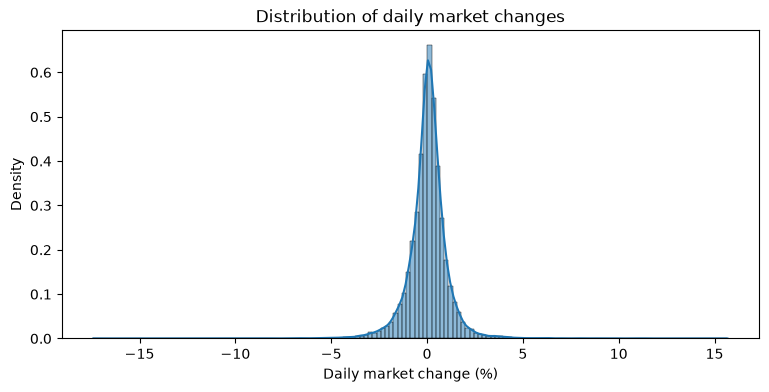

In [30]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

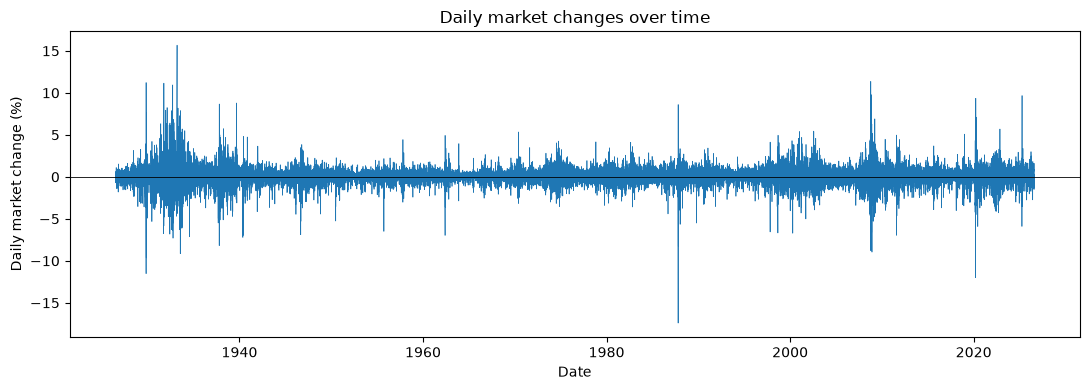

In [31]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

##### *#1 Answers*

In [32]:
# 1. categories for up and down

df["y_t"] = np.where(
    df["market_return_pct"] > 0,
    "Up",
    "Down"
)

df["y_tp1"] = df["y_t"].shift(-1)

df.head()

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,y_t,y_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Up,Up
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Up,Up
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Up,Up
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Up,Up
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Up,Down


In [33]:
# 2. compute joint PMF and marginals

pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize = True,
    margins = True
)

y_tp1,Down,Up,All
y_t,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [34]:
# calculate conditional PMFs
pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize="index"
)

y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


*3. Are up transitions more or less common than down transitions?*
* Based on the marginal probabilities at the bottom, up transitions are **more common** than down transitions (54.7% vs 45.3%). 

*4. Are you more likely to transition to an Up day from a Down or Up day?*
* Based on the conditional probabilities, you're more likely to transition to an Up from an **Up day** (58.3% vs 50.3% for Down -> Up).

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

##### *#2 Answers*

In [35]:
# group market returns into bins
df['return_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
)
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

df.head()

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,y_t,y_tp1,return_bin
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,Near zero,Small gain,Near zero
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,Small gain,Small gain,Small gain
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,Small gain,Near zero,Small gain
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,Near zero,Small gain,Near zero
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,Small gain,Small loss,Small gain


In [36]:
# count how many days per bin
df["y_t"].value_counts()

y_t
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64

*How many days fall into each of the five bins? Which are the most or least common?*
* 9785 days fall into 'Small gain', 7452 days fall into 'Small loss', 3441 days fall into 'Near zero', 2859 days fall into 'Large gain', and 2759 days fall into 'Large loss'. **Small gain and Small loss are the two most common, which Small gain being the most common overall.**

In [37]:
# calculate joint PMFs and marginals 

pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize = True,
    margins = True
)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


*Which transitions are most likely to occur?*
* The most likely transitions are:  

    * Small gain -> Small gain (15.9%)
    * Small gain -> Small loss (10%)
    * Small loss -> Small gain (9.7%)
    * Small loss -> Small loss (8.8%)


In [38]:
# compute conditional PMFs

pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize = "index"
)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
y_t,,,,,
Large loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small gain,0.067150,0.268908,0.147895,0.428455,0.087592
Large gain,0.127317,0.234697,0.107030,0.347674,0.183281


*For each current state, which two future states are the most likely?*
* Two future states (most likely):
    * Large loss: Small gain (26.4%) and Small loss (25.9%)
    * Small loss: Small gain (34.5%) and Small loss (31.2%)
    * Near zero: Small gain (37.6%) and Small loss (32%)
    * Small gain: Small gain (42.8%) and Small loss (26.8%)
    * Large gain: Small gain (34.7%) and Small loss (23.4%)

*Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?*
* Large loss row: The closest row to uniform, with Large loss/gain close to 20% and Small loss/gain close to 25% (but near zero is only 8%); this would be the hardest to predict the next state (could be small loss/gain or large loss/gain)
* Small loss row: Not very uniform; small loss/gain are above 30% and the other three hover around 10%; relatively easy to predict next state (small loss or small gain)
* Near zero row: Not very uniform; small loss/gain are above 30% and the other three hover around 10%; relatively easy to predict next state (small loss or small gain)
* Small gain row: not uniform; small gain is 42% whereas small loss is 26%, the other three are between 6-14%; relatively easy to predict (probably small gain)
* Large gain row: The second closest to uniform; small loss is 23%, small gain is 34%, and large gain is 18% and the other two are close to 10%; not as easy to predict next state (small gain/loss or large gain)

In [39]:
# compute conditional expectations

df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
df.groupby('y_t', observed=False)['market_return_pct_tp1'].describe()

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


*Given the current state, what are the expected percent returns for tomorrow?*
* Large loss: -0.038%, Small loss: -0.043%, Near zero: 0.015%, Small gain: 0.106%, Large gain: 0.163%  

*How do the min and max values for tomorrow vary across states?* 
* Large loss and large gains have the most variation. If today is large loss, tomorrow's percent return can vary by -17.41% to 11.22%. If today is Large gain, tomorrow's percent return can vary by -12% to 15.67%. Small gain has similar min and max (-8.25% vs + 8.67%), and small loss has similar, slightly larger min and max (-11.23% vs + 11.36%). Finally, if today is near zero, tomorrow's percent return can vary by -8.19% to 5.4%.  

*Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice.*
* Large loss and large gain have the highest SDs (1.72 and 1.38) (followed by small loss at 1.00). This suggests when market percentages are at their most extreme, there's more volatility for the next-day market percentages. Similarly, for small loss/gain, their standard deviations are smaller (around 0.83), which matches that there's less volatility the day after one of those.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

##### *#3 Answers*

In [40]:
# create 21 category bins

df["y_t"] = pd.qcut(
    df['market_return_pct'],
    q = 21
)

df["y_tp1"] = df["y_t"].shift(-1)

df.head()

,date,year,month,month_start,trading_day_of_month,mkt_excess_return_pct,risk_free_return_pct,market_return_pct,absolute_market_return_pct,y_t,y_tp1,return_bin,market_return_pct_tp1
0,1926-07-01,1926,7,1926-07-01,1,0.09,0.01,0.10,0.10,"(0.04, 0.11]","(0.44, 0.54]",Near zero,0.46
1,1926-07-02,1926,7,1926-07-01,2,0.45,0.01,0.46,0.46,"(0.44, 0.54]","(0.11, 0.18]",Small gain,0.18
2,1926-07-06,1926,7,1926-07-01,3,0.17,0.01,0.18,0.18,"(0.11, 0.18]","(0.04, 0.11]",Small gain,0.10
3,1926-07-07,1926,7,1926-07-01,4,0.09,0.01,0.10,0.10,"(0.04, 0.11]","(0.18, 0.26]",Near zero,0.23
4,1926-07-08,1926,7,1926-07-01,5,0.22,0.01,0.23,0.23,"(0.18, 0.26]","(-0.78, -0.57]",Small gain,-0.70


[Text(0.5, 1.0, 'Joint PMF')]

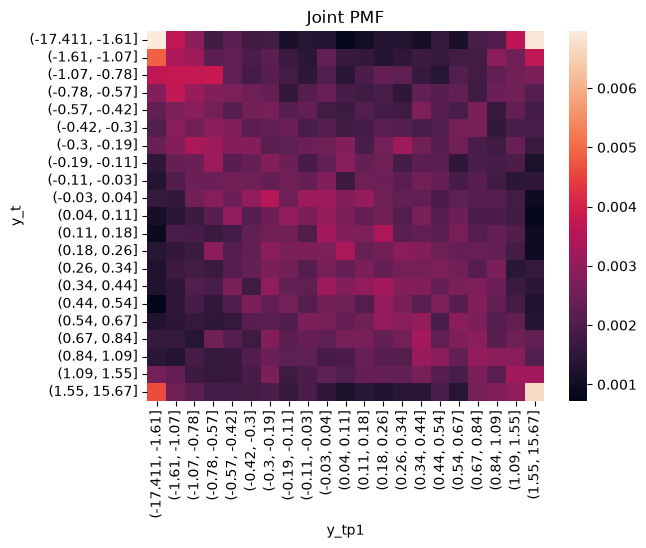

In [41]:
# joint PMF heatmap

tab = pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize = True
)

sns.heatmap(tab).set(title='Joint PMF')

[Text(0.5, 1.0, 'Centered Joint PMF')]

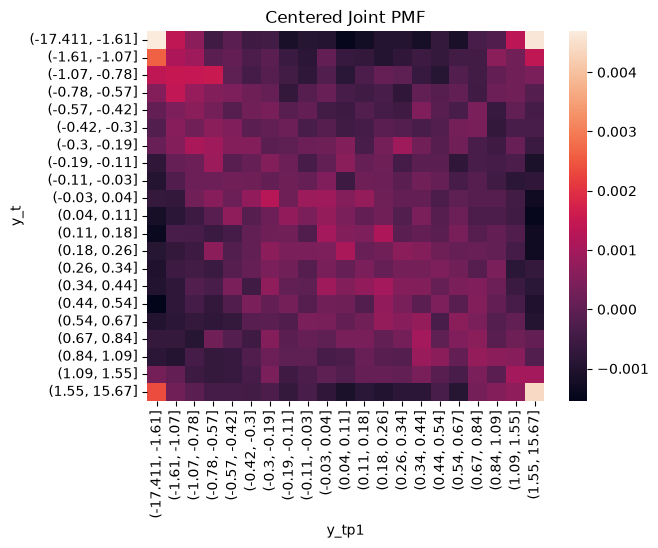

In [42]:
# centered joint heatmap
tab_centered = tab - 1 / 21**2

sns.heatmap(tab_centered).set(title='Centered Joint PMF')

*Do you see any obvious patterns? Explain. Try subtracting* 1/21**2 *from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.*
* The original and normalized joint PMF heatmaps look very similar. They don't show a super noticable diagonal pattern; instead, the corners are where the highest probabilities are clustered. This means that it's more likely for extreme values to transition to similar extreme values the next day.

[Text(0.5, 1.0, 'Conditional PMF')]

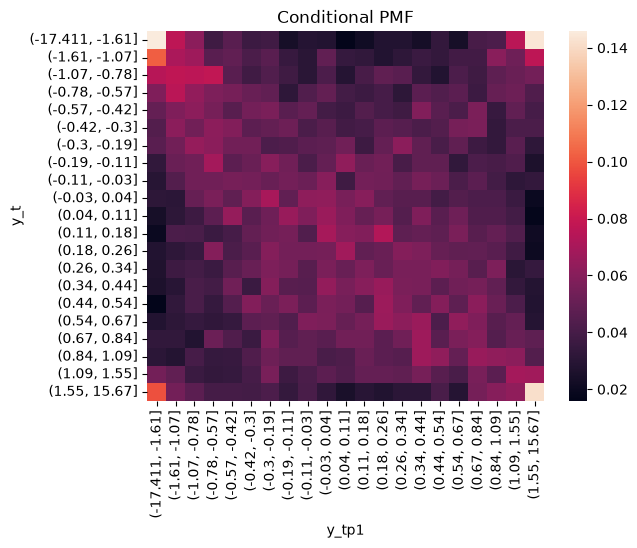

In [43]:
# conditional PMF heatmap

tab = pd.crosstab(
    df["y_t"],
    df["y_tp1"],
    normalize = "index"
)

sns.heatmap(tab).set(title='Conditional PMF')

[Text(0.5, 1.0, 'Centered Conditional PMF')]

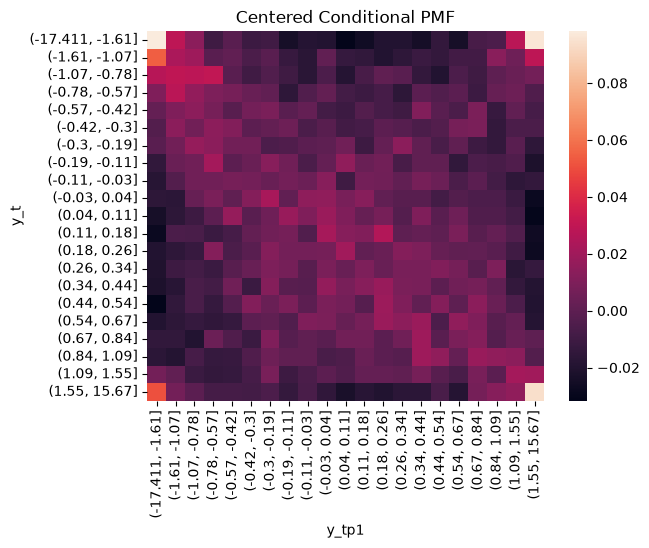

In [44]:
# centered conditional PMF heatmap

tab_centered = tab - 1 / 21

sns.heatmap(tab_centered).set(title='Centered Conditional PMF')

*Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.*
* Before normalizing, 

In [45]:
# compute min, mean, max values

*For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain.*

In [46]:
# compute standard deviations

*For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain.*
* answer  

*How easy is it to predict the market?*
* answer